# Análise Epidemiológica e Distribuição de Medicamentos na Farmácia Básica

**Projeto:** Gestão da Assistência Farmacêutica

**Autoras:** Beatriz Goulart e Esther de Oliveira  

**Arquivo de Origem:** `dispensacao_analitico.csv`  

---

## Contexto e Objetivos
A nomenclatura técnica de medicamentos (princípios ativos) em bases analíticas dificulta a interpretação gestora e o acesso público à informação.

Esta análise categoriza os registros de dispensação em **Perfis de Cuidado e Tratamento** funcionais (ex.: *Saúde Cardiovascular*, *Controle Metabólico*, *Infectologia*), visando:
1. Mapear as linhas de cuidado com maior demanda de suprimentos.
2. Identificar a distribuição de dispensação entre os estabelecimentos de saúde.
3. Garantir transparência sobre o volume de itens não categorizados (`Outros / Não Classificado`).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

file_path = "../../data/processed/dispensacao_analitico.csv"

try:
    df = pd.read_csv(file_path)
    print(f"Base carregada com sucesso: {df.shape[0]} registros e {df.shape[1]} colunas.")
    print("\nColunas encontradas na base:")
    print(df.columns.tolist())
except FileNotFoundError:
    print(f"Arquivo não encontrado em {file_path}. Verifique o caminho dos dados.")

Base carregada com sucesso: 220815 registros e 25 colunas.

Colunas encontradas na base:
['competencia_inicial', 'competencia_final', 'ups_nome', 'ups_codigo', 'bairro_nome', 'bairro_codigo', 'centro_custo_nome', 'centro_custo_codigo', 'material_nome', 'material_nome_base', 'material_descricao_complementar', 'material_tipo', 'classe_terapeutica', 'tipo_tratamento', 'material_codigo', 'data', 'saida', 'usuario', 'fabricante_codigo', 'fabricante_nome', 'lote', 'numero_receita', 'validade', 'quantidade', 'custo_medio']


### 1. Classificação por Perfil de Cuidado
Mapeamento dos princípios ativos em eixos terapêuticos, mantendo a categoria de não classificados visível.

In [3]:
if 'material_nome' in df.columns:
    df['nome_completo_med'] = (
        df['material_nome'].fillna('').astype(str) + ' ' + 
        df['material_descricao_complementar'].fillna('').astype(str)
    ).str.strip()
    coluna_med = 'nome_completo_med'
else:
    coluna_med = [col for col in df.columns if any(k in col.upper() for k in ['MEDICAMENTO', 'PRODUTO', 'DESCRICAO'])][0]

mapeamento_cuidados = {
    "Cardiovascular / Hipertensão": [
        "LOSARTANA", "ENALAPRIL", "ATENOLOL", "HIDROCLOROTIAZIDA", 
        "ANLODIPINO", "CAPTOPRIL", "SINVASTATINA", "PROPRANOLOL", 
        "FUROSEMIDA", "ESPIRONOLACTONA", "CARVEDILOL"
    ],
    "Controle de Diabetes": [
        "METFORMINA", "GLIBENCLAMIDA", "INSULINA", "GLICLAZIDA", "CANETA INSULINA"
    ],
    "Saúde Mental / Psicotrópicos": [
        "FLUOXETINA", "SERTRALINA", "AMITRIPTILINA", "CLONAZEPAM", 
        "DIAZEPAM", "HALOPERIDOL", "RISPERIDONA", "CARBONATO DE LITIO",
        "VALPROATO", "CARBAMAZEPINA", "CLORPROMAZINA"
    ],
    "Dor e Inflamação": [
        "DIPIRONA", "PARACETAMOL", "IBUPROFENO", "DICLOFENACO", "TRAMADOL", "PREDNISONA"
    ],
    "Anti-infecciosos / Antibióticos": [
        "AMOXICILINA", "AZITROMICINA", "CEFALEXINA", "CIPROFLOXACINO", "SULFAMETOXAZOL"
    ],
    "Saúde Respiratória": [
        "SALBUTAMOL", "BECLOMETASONA", "BUDESONIDA", "IPRATROPIO"
    ],
    "Gastrointestinal": [
        "OMEPRAZOL", "HIDROXIDO DE ALUMINIO", "RANITIDINA", "METOCLOPRAMIDA"
    ]
}

def normalizar_texto(txt):
    if not isinstance(txt, str):
        return ""
    return unicodedata.normalize('NFKD', txt).encode('ASCII', 'ignore').decode('ASCII').upper()

def classificar_medicamento(nome_medicamento):
    nome_norm = normalizar_texto(nome_medicamento)
    if not nome_norm:
        return "Outros / Não Classificados"
    for perfil, termos in mapeamento_cuidados.items():
        for termo in termos:
            if termo in nome_norm:
                return perfil
    return "Outros / Não Classificados"

df['perfil_cuidado'] = df[coluna_med].apply(classificar_medicamento)

### 2. Distribuição dos Perfis de Cuidado
Volume total dispensado por perfil terapêutico identificado.

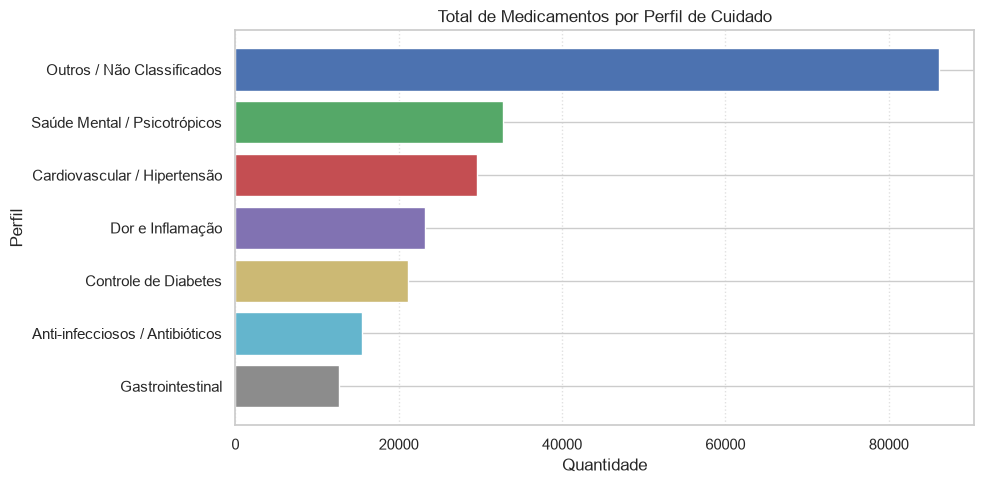

,Perfil de Cuidado,Total de Dispensações
0,Outros / Não Classificados,86122
1,Saúde Mental / Psicotrópicos,32747
2,Cardiovascular / Hipertensão,29555
3,Dor e Inflamação,23168
4,Controle de Diabetes,21075
5,Anti-infecciosos / Antibióticos,15524
6,Gastrointestinal,12624


In [12]:
contagem_perfis = df['perfil_cuidado'].value_counts().reset_index()
contagem_perfis.columns = ['Perfil de Cuidado', 'Total de Dispensações']

plt.figure(figsize=(10, 5))
cores = ['#4C72B0', '#55A868', '#C44E52', '#8172B2', '#CCB974', '#64B5CD', '#8C8C8C', '#E1974C']

plt.barh(
    contagem_perfis['Perfil de Cuidado'], 
    contagem_perfis['Total de Dispensações'], 
    color=cores[:len(contagem_perfis)]
)

plt.title('Total de Medicamentos por Perfil de Cuidado', fontsize=12)
plt.xlabel('Quantidade')
plt.ylabel('Perfil')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

display(contagem_perfis)

Em contrapartida aos grandes agregados de dispensação (hipertensão arterial, diabetes mellitus e analgésicos comuns), a análise da cauda longa revela perfis clínicos com volumes reduzidos de dispensação no município.

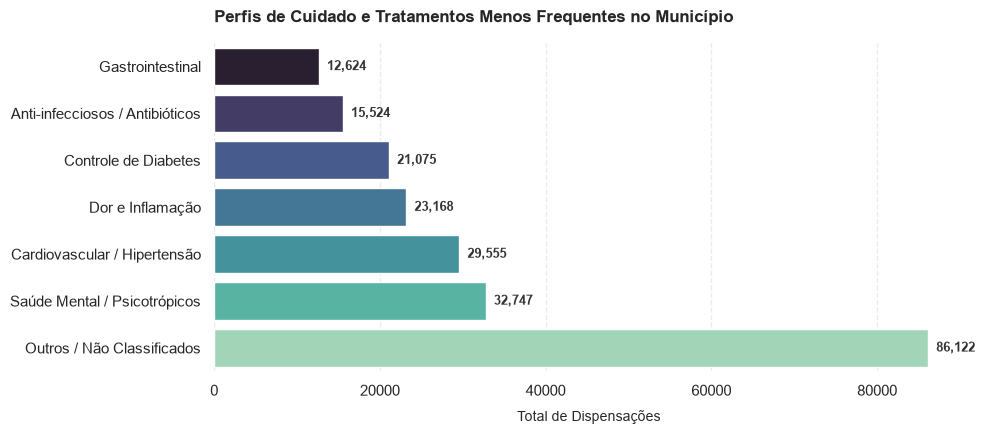

,Perfil de Cuidado,Total de Dispensações
6,Gastrointestinal,12624
5,Anti-infecciosos / Antibióticos,15524
4,Controle de Diabetes,21075
3,Dor e Inflamação,23168
2,Cardiovascular / Hipertensão,29555
1,Saúde Mental / Psicotrópicos,32747
0,Outros / Não Classificados,86122


In [13]:
contagem_perfis = df['perfil_cuidado'].value_counts().reset_index()
contagem_perfis.columns = ['Perfil de Cuidado', 'Total de Dispensações']

perfis_raros = contagem_perfis[contagem_perfis['Perfil de Cuidado'] != 'Não Classificado'].tail(8)
perfis_raros = perfis_raros.sort_values(by='Total de Dispensações', ascending=True)

plt.figure(figsize=(10, 4.5), dpi=100)

ax = sns.barplot(
    data=perfis_raros,
    x='Total de Dispensações',
    y='Perfil de Cuidado',
    palette='mako',
    hue='Perfil de Cuidado',
    legend=False
)

sns.despine(left=True, bottom=True)
ax.xaxis.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
ax.yaxis.grid(False)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f'{int(width):,}',
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(6, 0),
            textcoords='offset points',
            ha='left',
            va='center',
            fontsize=9,
            fontweight='bold',
            color='#333333'
        )

plt.title('Perfis de Cuidado e Tratamentos Menos Frequentes no Município', fontsize=12, fontweight='bold', pad=15, loc='left')
plt.xlabel('Total de Dispensações', fontsize=10, labelpad=8)
plt.ylabel('')
plt.tight_layout()
plt.show()

display(perfis_raros)

### 3. Composição dos Medicamentos por Perfil
Detalhamento dos principais medicamentos associados a cada grupo de cuidado.

In [5]:
top_medicamentos = (
    df.groupby(['perfil_cuidado', coluna_med])
    .size()
    .reset_index(name='contagem')
    .sort_values(['perfil_cuidado', 'contagem'], ascending=[True, False])
    .groupby('perfil_cuidado')
    .head(5)
)

display(top_medicamentos)

,perfil_cuidado,nome_completo_med,contagem
3,Anti-infecciosos / Antibióticos,AMOXICILINA+CLAVULANATO - 500/125MG - COMPRIMI...,4399
1,Anti-infecciosos / Antibióticos,AMOXICILINA - AMOXICILINA - 500 MG - COMPRIMID...,2590
5,Anti-infecciosos / Antibióticos,AZITROMICINA - AZITROMICINA 500 MG COMPRIMIDO ...,2403
7,Anti-infecciosos / Antibióticos,CEFALEXINA - 500MG - COMPRIMIDO 500MG,1783
8,Anti-infecciosos / Antibióticos,CIPROFLOXACINO - 500MG - COMPRIMIDO 500MG,1177
22,Cardiovascular / Hipertensão,SINVASTATINA - 20MG - COMPRIMIDO 20MG,7537
20,Cardiovascular / Hipertensão,ESPIRONOLACTONA - 25MG - COMPRIMIDO 25MG,4333
12,Cardiovascular / Hipertensão,ANLODIPINO - 5MG - COMPRIMIDO 5MG,4026
18,Cardiovascular / Hipertensão,ENALAPRIL - 20MG - COMPRIMIDO 20MG,2677
21,Cardiovascular / Hipertensão,FUROSEMIDA - 40MG - COMPRIMIDO 40MG,2274


### 4. Percentual de Cada Linha de Cuidado
Visão da fatia de participação de cada grupo terapêutico no volume total dispensado.

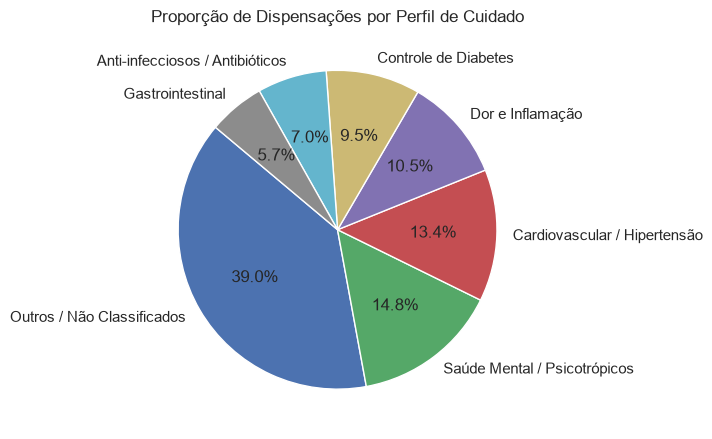

In [6]:
plt.figure(figsize=(7, 7))

plt.pie(
    contagem_perfis['Total de Dispensações'], 
    labels=contagem_perfis['Perfil de Cuidado'], 
    autopct='%1.1f%%', 
    startangle=140,
    colors=cores[:len(contagem_perfis)]
)

plt.title('Proporção de Dispensações por Perfil de Cuidado', fontsize=12)
plt.tight_layout()
plt.show()

### 5. Os 10 Medicamentos Mais Dispensados no Total
Ranking geral dos princípios ativos ou produtos mais retirados pela população.

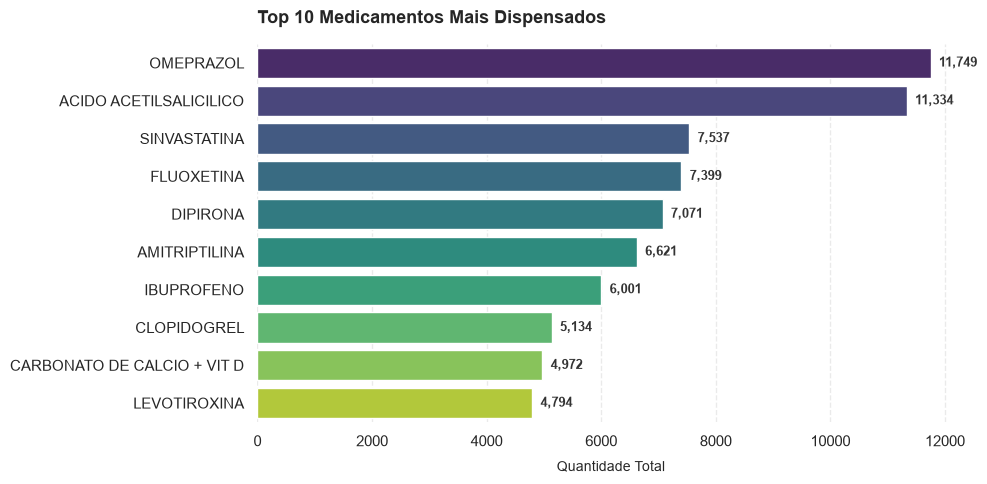

In [ ]:
top_10_geral = df[coluna_med].value_counts().head(10).reset_index()
top_10_geral.columns = ['Medicamento', 'Quantidade']

# Mantém apenas o texto antes do primeiro "-" e remove espaços extras
top_10_geral['Medicamento'] = top_10_geral['Medicamento'].str.split('-').str[0].str.strip()

plt.figure(figsize=(10, 5), dpi=100)

ax = sns.barplot(
    data=top_10_geral,
    x='Quantidade',
    y='Medicamento',
    hue='Medicamento',
    palette='viridis',
    legend=False
)

sns.despine(left=True, bottom=True)
ax.xaxis.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
ax.yaxis.grid(False)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(
            f'{int(width):,}',
            xy=(width, p.get_y() + p.get_height() / 2),
            xytext=(6, 0),
            textcoords='offset points',
            ha='left',
            va='center',
            fontsize=9,
            fontweight='bold',
            color='#333333'
        )

plt.title('Top 10 Medicamentos Mais Dispensados', fontsize=13, fontweight='bold', pad=15, loc='left')
plt.xlabel('Quantidade Total', fontsize=10, labelpad=8)
plt.ylabel('')
plt.tight_layout()
plt.show()

### 6. Análise por Período ou Unidade de Saúde
Identificação de colunas de data ou local para avaliar variações temporais ou geográficas.

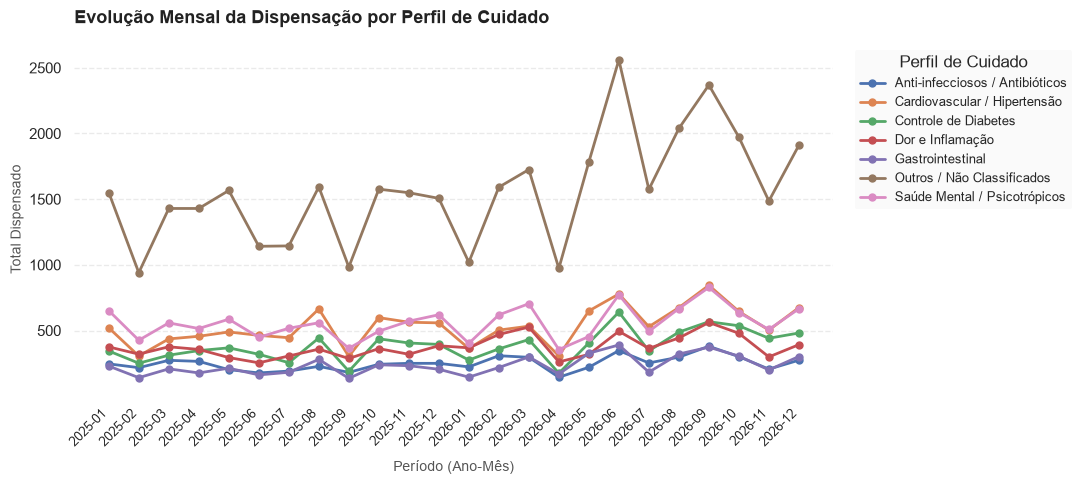

perfil_cuidado,Anti-infecciosos / Antibióticos,Cardiovascular / Hipertensão,Controle de Diabetes,Dor e Inflamação,Gastrointestinal,Outros / Não Classificados,Saúde Mental / Psicotrópicos
periodo_mes,,,,,,,
2025-01,246,520,344,375,229,1550,651
2025-02,217,306,251,320,141,940,426
2025-03,273,436,312,376,208,1429,558
2025-04,265,456,347,356,177,1429,515
2025-05,202,489,368,294,213,1566,586
2025-06,177,463,319,254,162,1141,448
2025-07,191,445,255,306,182,1144,517
2025-08,227,664,443,358,280,1593,559
2025-09,181,303,190,287,136,983,364


In [ ]:
colunas_data = [col for col in df.columns if any(k in col.upper() for k in ['DATA', 'MES', 'ANO', 'PERIODO'])]

if colunas_data:
    col_data = colunas_data[0]
    
    df_tempo = df.copy()
    df_tempo[col_data] = pd.to_datetime(df_tempo[col_data], errors='coerce', dayfirst=True)
    df_tempo = df_tempo.dropna(subset=[col_data])
    
    df_tempo['periodo_mes'] = df_tempo[col_data].dt.to_period('M')
    tabela_tempo = pd.crosstab(df_tempo['periodo_mes'], df_tempo['perfil_cuidado'])
    
    fig, ax = plt.subplots(figsize=(11, 5), dpi=100)
    
    for perfil in tabela_tempo.columns:
        ax.plot(
            tabela_tempo.index.astype(str), 
            tabela_tempo[perfil], 
            marker='o', 
            linewidth=2,
            markersize=5,
            label=perfil
        )
    
    sns.despine(left=True, bottom=True)
    ax.yaxis.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
    ax.xaxis.grid(False)
    
    plt.title('Evolução Mensal da Dispensação por Perfil de Cuidado', fontsize=13, fontweight='bold', pad=15, loc='left', color='#222222')
    plt.xlabel('Período (Ano-Mês)', fontsize=10, labelpad=8, color='#555555')
    plt.ylabel('Total Dispensado', fontsize=10, color='#555555')
    plt.xticks(rotation=45, ha='right', fontsize=9)
    
    plt.legend(
        title='Perfil de Cuidado',
        bbox_to_anchor=(1.02, 1),
        loc='upper left',
        frameon=True,
        facecolor='#f9f9f9',
        edgecolor='none',
        fontsize=9
    )
    
    plt.tight_layout()
    plt.show()
    
    display(tabela_tempo)
else:
    print("Coluna de data não encontrada.")

### 7. Distribuição por Estabelecimento de Saúde
Comparação do volume e dos perfis de cuidado atendidos nas principais unidades de saúde.

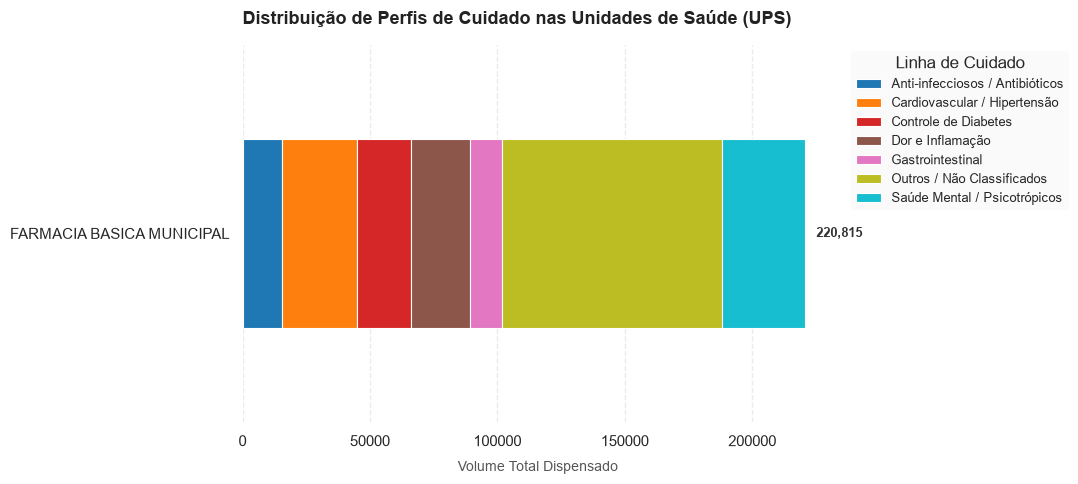

perfil_cuidado,Anti-infecciosos / Antibióticos,Cardiovascular / Hipertensão,Controle de Diabetes,Dor e Inflamação,Gastrointestinal,Outros / Não Classificados,Saúde Mental / Psicotrópicos
ups_nome,,,,,,,
FARMACIA BASICA MUNICIPAL,15524,29555,21075,23168,12624,86122,32747


In [ ]:
col_local = 'ups_nome'

top_locais = df[col_local].value_counts().head(5).index
df_top_locais = df[df[col_local].isin(top_locais)]

tabela_local = pd.crosstab(df_top_locais[col_local], df_top_locais['perfil_cuidado'])
tabela_local = tabela_local.loc[tabela_local.sum(axis=1).sort_values(ascending=True).index]

fig, ax = plt.subplots(figsize=(11, 5), dpi=100)

tabela_local.plot(
    kind='barh',
    stacked=True,
    ax=ax,
    colormap='tab10',
    edgecolor='white',
    linewidth=0.8
)

sns.despine(left=True, bottom=True)
ax.xaxis.grid(True, linestyle='--', alpha=0.4, color='#cccccc')
ax.yaxis.grid(False)

for i, total in enumerate(tabela_local.sum(axis=1)):
    ax.annotate(
        f'{int(total):,}',
        xy=(total, i),
        xytext=(8, 0),
        textcoords='offset points',
        ha='left',
        va='center',
        fontsize=9,
        fontweight='bold',
        color='#333333'
    )

plt.title('Distribuição de Perfis de Cuidado nas Unidades de Saúde (UPS)', fontsize=13, fontweight='bold', pad=15, loc='left', color='#222222')
plt.xlabel('Volume Total Dispensado', fontsize=10, labelpad=8, color='#555555')
plt.ylabel('', fontsize=10)

plt.legend(
    title='Linha de Cuidado',
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
    facecolor='#f9f9f9',
    edgecolor='none',
    fontsize=9
)

plt.tight_layout()
plt.show()

display(tabela_local)